In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pickle
import jax
import jax.numpy as jnp
import jax.random as jr

from experiments.slam.image.setup import setup

from rp_slam import datasets
from rp_slam.training import Trainer
from rp_slam.recognition.networks import MLP, CNN
from rp_slam.utils.krr import sweep_krr

## Sensor Dataset

Min: 0.0, Max: 0.9998999238014221


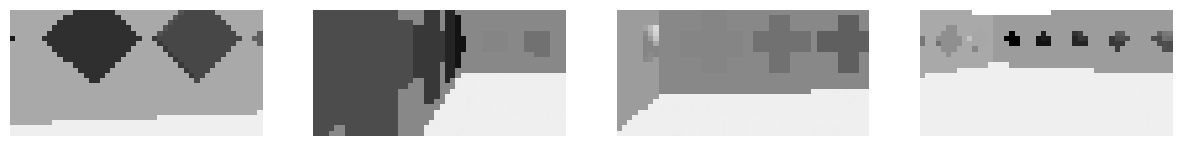

In [2]:
DATASEED = 0
DATASET = datasets.load_dataset("greyscale", DATASEED)
# DATASET = DATASET.standardized_data
print(f"Min: {DATASET.train_data[0].min()}, Max: {DATASET.train_data[0].max()}")

fig, ax = plt.subplots(1, 4, figsize=(15, 5))
for i in range(4):
    ax[i].imshow(DATASET.train_data[0][0, i * 30], cmap="grey", vmin=0, vmax=1)
    ax[i].axis("off")
plt.show()

## Helper Functions

In [3]:
def train(
    kernel: str,
    latent_dim: int = 32,
    batch_size: int = 25,
    num_iter: int = 25000,
    seed: int = 1234,
    prior_lr: float = 5e-5,
    rec_lr: float = 5e-5,
    plot: bool = True
):
    
    CONFIG, MODEL_FE = setup(
        kernel=kernel,
        latent_dim=latent_dim, 
        batch_size=batch_size, 
        num_iter=num_iter, 
        seed=seed,
        prior_lr=prior_lr, 
        rec_lr=rec_lr
    )
    
    trainer = Trainer(model=MODEL_FE, config=CONFIG)
    trainer.fit(data=DATASET.train_data, use_pbar=True)

    # plot loss over time
    if plot:
        plt.figure(figsize=(14, 3))
        plt.plot(trainer.loss_tot)
        plt.title("Training loss over iterations")
        plt.xlabel("Iteration")
        plt.ylabel("Loss")
        plt.show()
    
    return trainer

In [9]:
def kernel_ridge_regression(
    x,
    val_x,
    plot: bool = True
):
    
    sigma_range = np.arange(0.01, 4, 0.1)
    lambda_range = np.arange(0.001, 0.2, 0.02)
    
    krr, scores = sweep_krr(
        x,
        DATASET.train_states,
        val_x,
        DATASET.val_states,
        sigma_range, 
        lambda_range,
        batch_frac=0.2
    )

    if plot:
        values = np.asarray(scores)
        sigmas = np.asarray(sigma_range)
        lambdas = np.asarray(lambda_range)

        fig, ax = plt.subplots(figsize=(10, 6))
        im = ax.imshow(values, origin="lower", aspect="auto", cmap="viridis")

        ax.set_xticks(np.arange(len(lambdas)))
        ax.set_xticklabels([f"{v:.3f}" for v in lambdas], rotation=45)

        rows = np.arange(0, len(sigmas), 4)
        ax.set_yticks(rows)
        ax.set_yticklabels([f"{sigmas[i]:.2f}" for i in rows])

        i, j = np.unravel_index(np.nanargmax(values), values.shape)
        ax.scatter(j, i, marker="x", color="red", s=100, linewidths=2)

        ax.set(xlabel=r"$\lambda$", ylabel=r"$\sigma$", title=f"Validation $R^2$ — best: {values[i, j]:.3f}")
        fig.colorbar(im, ax=ax, label=r"Mean $R^2$")
        plt.tight_layout()
        plt.show()

    return krr

In [5]:
def plot_visual_diagnostics(preds, truth, B: int = 3):

    preds = np.asarray(preds)
    truth = np.asarray(truth)
    D = preds.shape[-1]

    # Plot example trajectories in the location grid
    fig, axes = plt.subplots(1, B, figsize=(5 * B, 5), squeeze=False)

    for b, ax in enumerate(axes.ravel()):
        ax.plot(truth[b, :, 0], truth[b, :, 1], label="Truth")
        ax.plot(preds[b, :, 0], preds[b, :, 1], label="Predicted", alpha=0.7)
        ax.set(xlabel="x", ylabel="y", title=f"Series {b + 1}")
        ax.set_aspect("equal", adjustable="box")
        ax.legend(fontsize=6)

    plt.tight_layout()
    plt.show()

    # Plot fit
    fig, axes = plt.subplots(1, D, figsize=(4 * D, 4), squeeze=False)

    for d, ax in enumerate(axes.ravel()):
        x = truth[:, :, d].ravel()
        y = preds[:, :, d].ravel()

        # Least-squares line of best fit
        slope, intercept = np.polyfit(x, y, 1)
        x_fit = np.linspace(x.min(), x.max(), 100)
        y_fit = slope * x_fit + intercept

        # R-squared
        r2 = 1 - np.sum((y - (slope * x + intercept))**2) / np.sum((y - y.mean())**2)

        ax.scatter(x, y, s=3, alpha=0.3)
        ax.plot(x_fit, y_fit, color="red", lw=1.5, label=f"Fit ($R^2={r2:.3f}$)")
        ax.plot(x_fit, x_fit, "k--", lw=1, label="Ideal")

        ax.set_title(f"Dimension {d + 1}")
        ax.set_xlabel("Truth")
        ax.set_ylabel("Predicted")
        ax.legend(fontsize=12)

    plt.tight_layout()
    plt.show()

In [6]:
def save_parameters(trainer, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    with path.open("wb") as f:
        pickle.dump(jax.device_get(trainer.params), f)

def save_parameters(trainer, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    with path.open("wb") as f:
        pickle.dump(jax.device_get(trainer.params), f)


def load_trainer(
    path,
    kernel,
    latent_dim=32,
    batch_size=25,
    num_iter=25000,
    seed=1234,
    prior_lr=5e-5,
    rec_lr=5e-5,
):
    config, model = setup(
        kernel=kernel,
        latent_dim=latent_dim,
        batch_size=batch_size,
        num_iter=num_iter,
        seed=seed,
        prior_lr=prior_lr,
        rec_lr=rec_lr,
    )
    trainer = Trainer(model=model, config=config)

    with open(path, "rb") as f:
        trainer.params = jax.tree_util.tree_map(jnp.asarray, pickle.load(f))

    return trainer

## RPSSM

Training: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 25000/25000 [1:05:26<00:00,  6.37it/s, loss=1.28]


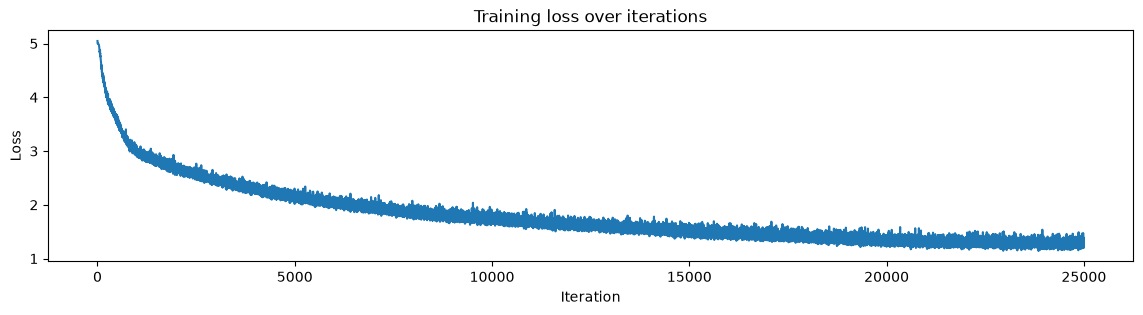

In [7]:
rpssm = train(kernel="rpssm")
save_parameters(rpssm, "checkpoints/rpssm.pkl")

Fitting KRR: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 300/300 [00:13<00:00, 21.72it/s, best_r2=0.8811]


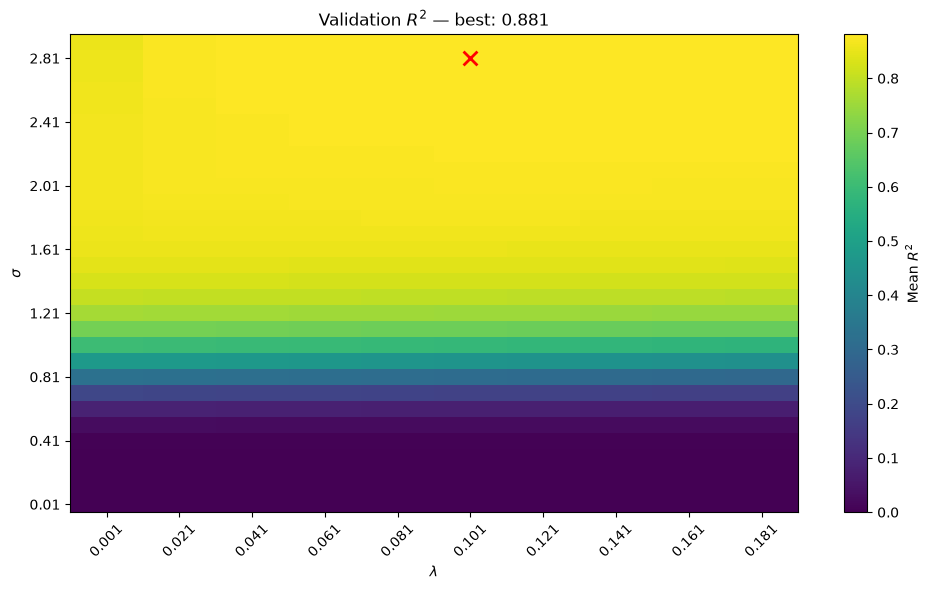

In [12]:
x = rpssm.apply(DATASET.train_data).params["means"]
val_x = rpssm.apply(DATASET.val_data).params["means"]
krr = kernel_ridge_regression(x, val_x)

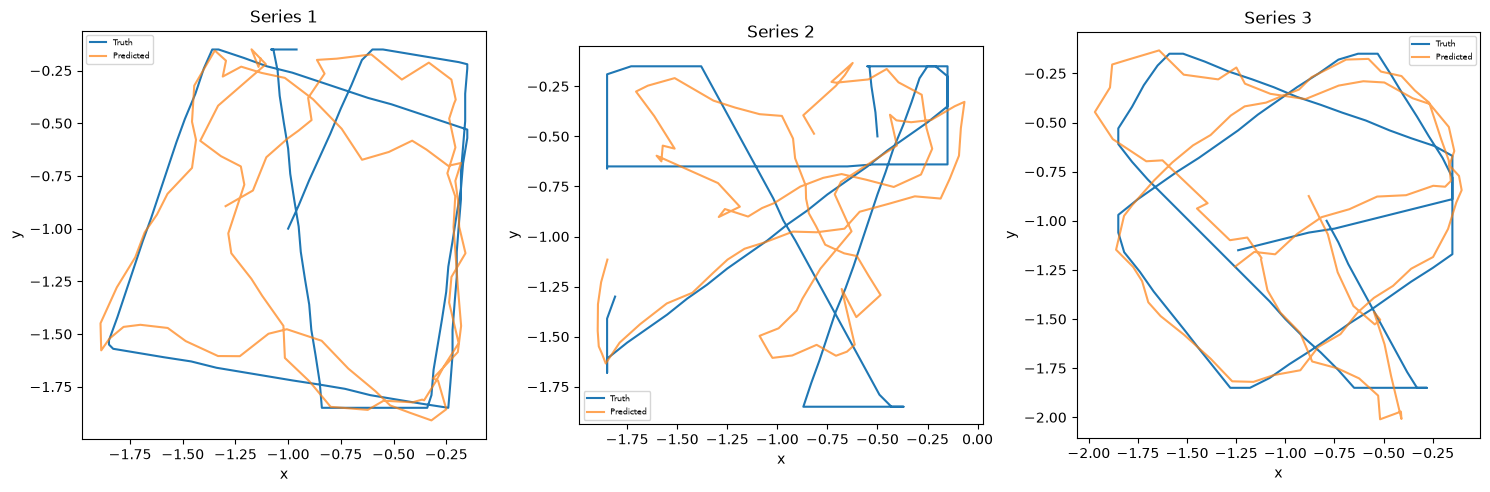

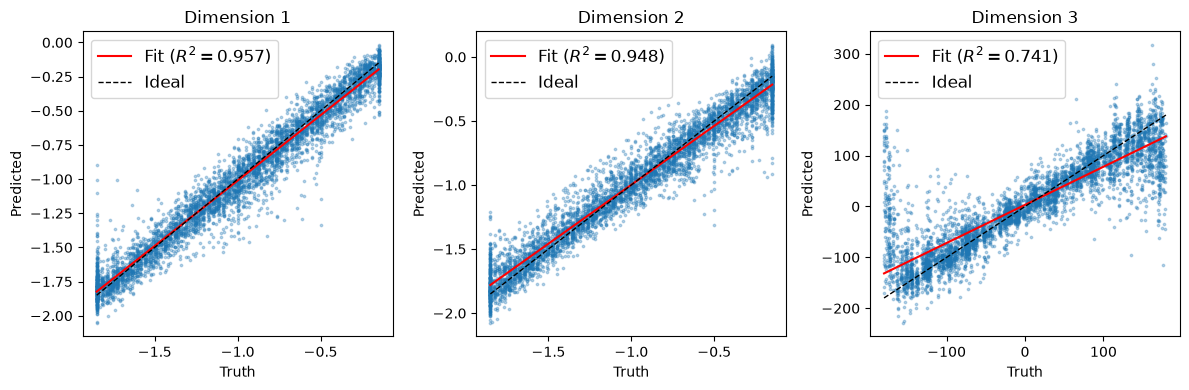

In [13]:
preds = krr.predict(val_x)
truth = DATASET.val_states
plot_visual_diagnostics(preds, truth)

## RAMPSSM

Training: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 25000/25000 [1:40:13<00:00,  4.16it/s, loss=-2.58]


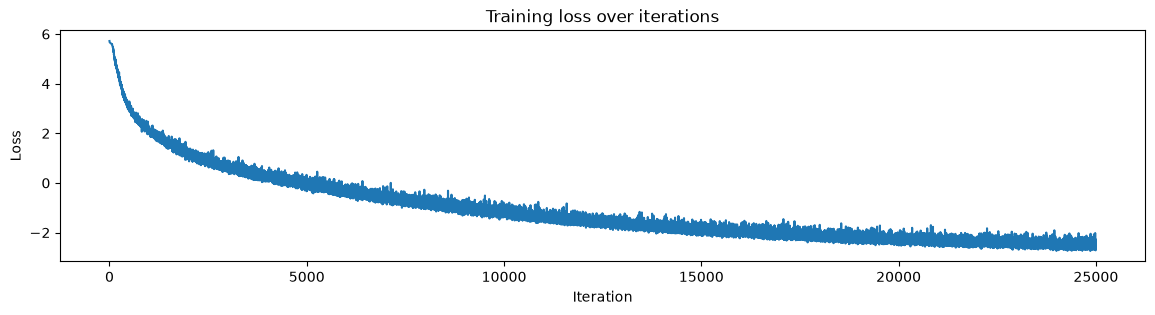

In [7]:
ramp = train(kernel="ramp")
save_parameters(ramp, "checkpoints/ramp.pkl")

Fitting KRR: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 400/400 [00:14<00:00, 28.27it/s, best_r2=0.6672]


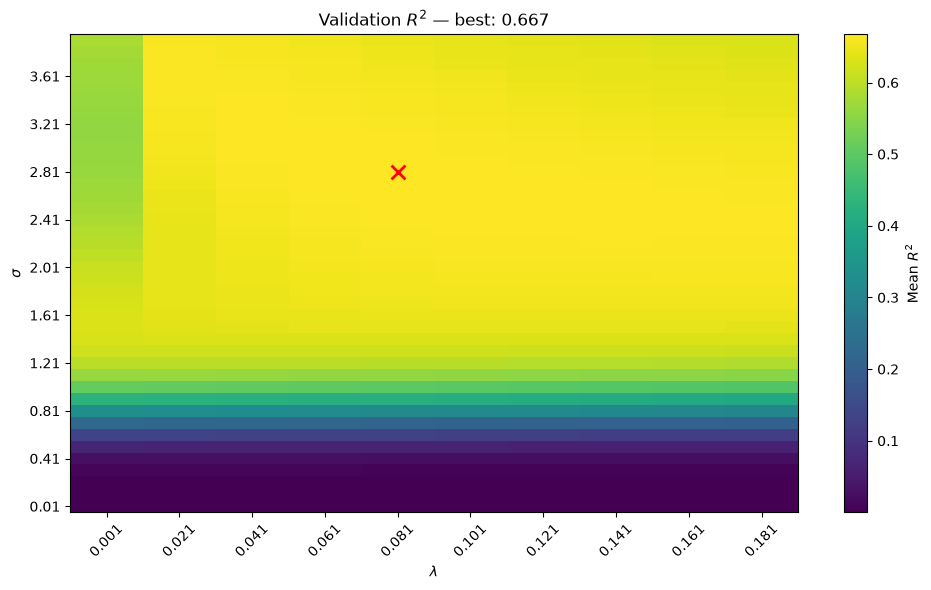

In [10]:
x = ramp.apply(DATASET.train_data).params["mean"]
val_x = ramp.apply(DATASET.val_data).params["mean"]
krr = kernel_ridge_regression(x, val_x)

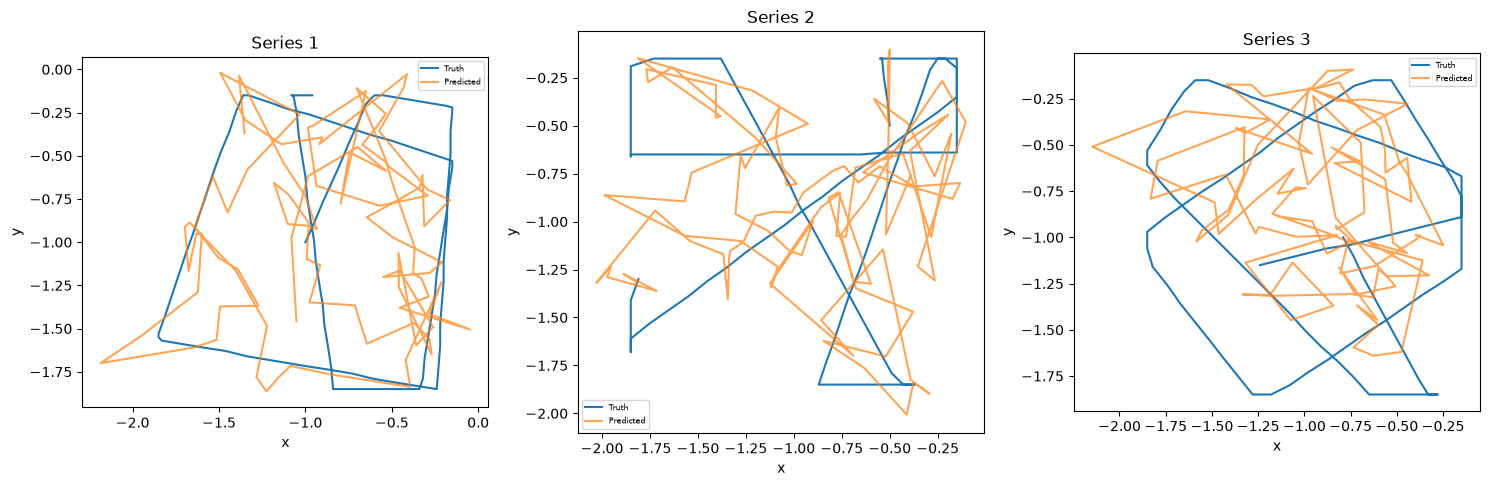

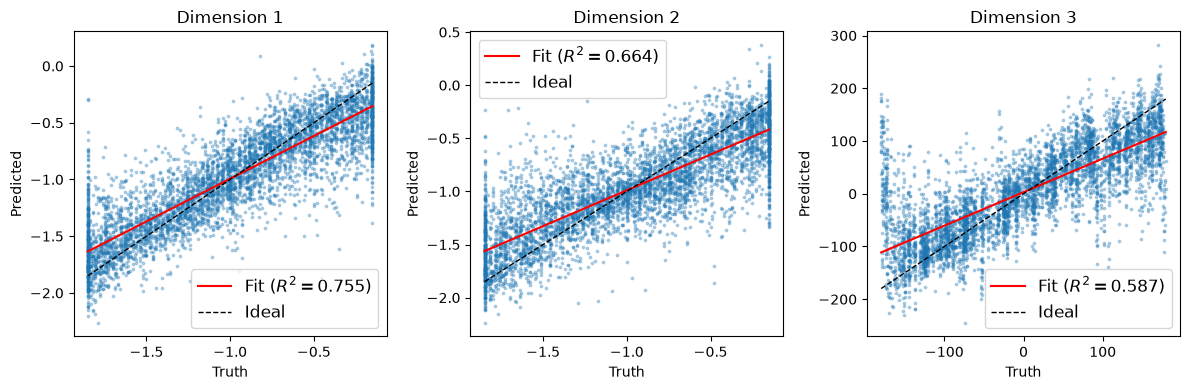

In [11]:
preds = krr.predict(val_x)
truth = DATASET.val_states
plot_visual_diagnostics(preds, truth)

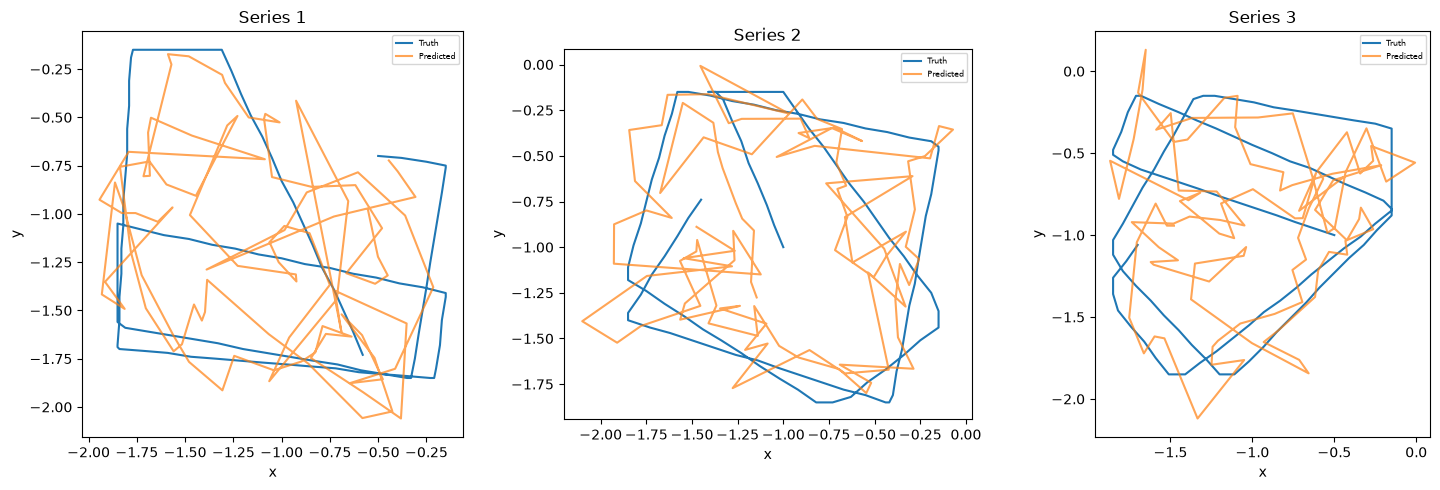

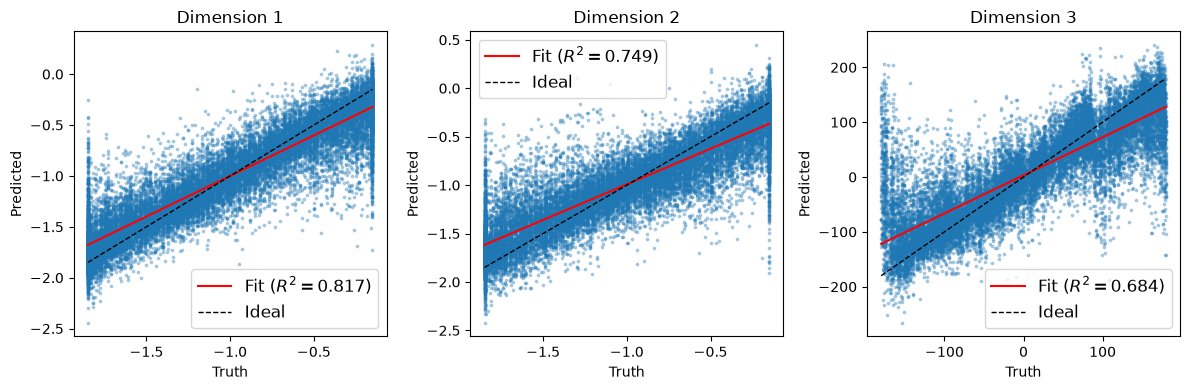

In [12]:
preds = krr.predict(x)
truth = DATASET.train_states
plot_visual_diagnostics(preds, truth)

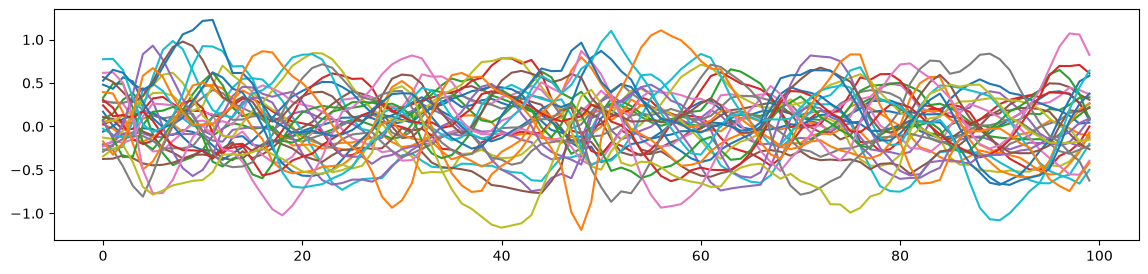

In [13]:
plt.figure(figsize=(14, 3))
plt.plot(x[0, :, :])
plt.show()